In [26]:
import pandas as pd
from sklearn import tree

df = pd.read_csv("weather_forecast.csv")

df.shape

(14, 5)

In [27]:
df.head(14)

,Outlook,Temperature,Humidity,Windy,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [28]:
# seperate input and output

# X - features(Outlook, Temperature, Humidity, Windy)
# y - target(Play)

X,y = df[['Outlook', 'Temperature', 'Humidity', 'Windy']],df['Play']

In [29]:
# Scikit-learn cannot directly work with text
# convert categorical values into numerical representation - one hot encoding

one_hot_data = pd.get_dummies(df[['Outlook', 'Temperature', 'Humidity', 'Windy']], drop_first = False)
one_hot_data_X = pd.get_dummies(X, drop_first=False)
one_hot_data_Y = pd.get_dummies(y, drop_first=True)

In [30]:
one_hot_data.head(20)

,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Windy_Strong,Windy_Weak
0,0,0,1,0,1,0,1,0,0,1
1,0,0,1,0,1,0,1,0,1,0
2,1,0,0,0,1,0,1,0,0,1
3,0,1,0,0,0,1,1,0,0,1
4,0,1,0,1,0,0,0,1,0,1
5,0,1,0,1,0,0,0,1,1,0
6,1,0,0,1,0,0,0,1,1,0
7,0,0,1,0,0,1,1,0,0,1
8,0,0,1,1,0,0,0,1,0,1
9,0,1,0,0,0,1,0,1,0,1


In [31]:
one_hot_data_X.head(20)

,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Windy_Strong,Windy_Weak
0,0,0,1,0,1,0,1,0,0,1
1,0,0,1,0,1,0,1,0,1,0
2,1,0,0,0,1,0,1,0,0,1
3,0,1,0,0,0,1,1,0,0,1
4,0,1,0,1,0,0,0,1,0,1
5,0,1,0,1,0,0,0,1,1,0
6,1,0,0,1,0,0,0,1,1,0
7,0,0,1,0,0,1,1,0,0,1
8,0,0,1,1,0,0,0,1,0,1
9,0,1,0,0,0,1,0,1,0,1


In [32]:
one_hot_data_Y.head(20)

,Yes
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


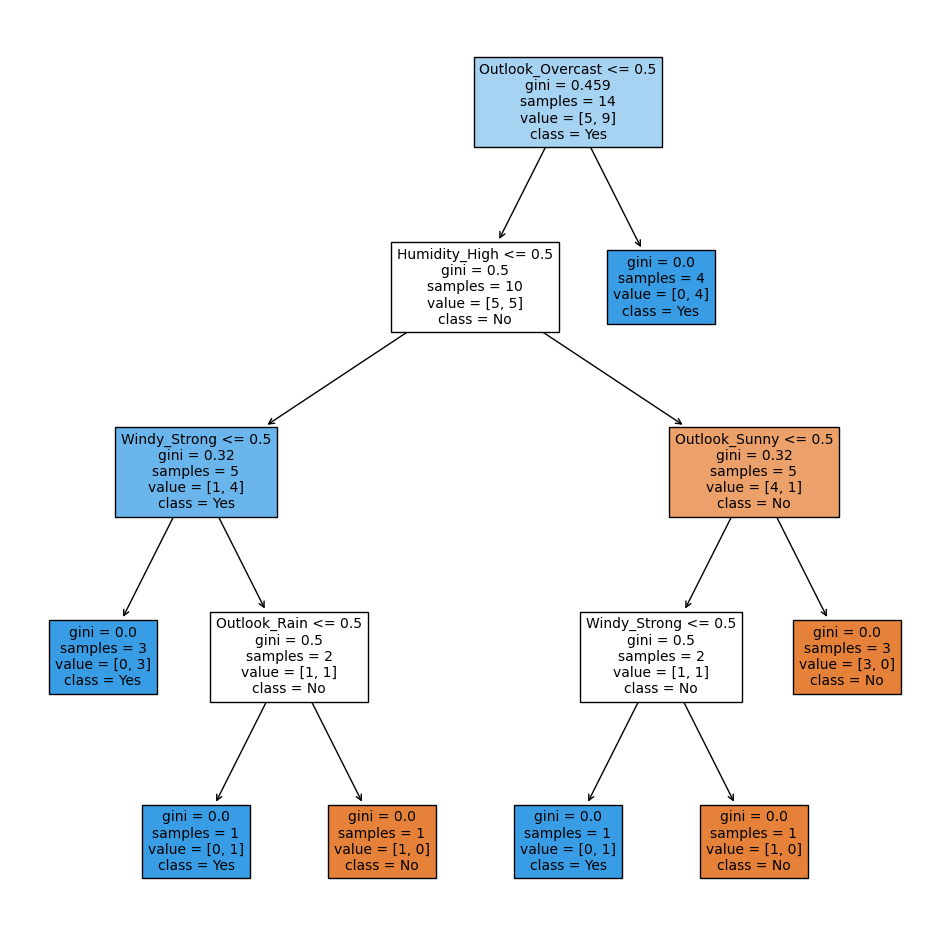

In [33]:
# creae the decision tree

import matplotlib.pyplot as plt

# creating a decision tree classifier

classifier = tree.DecisionTreeClassifier(criterion = 'gini')
#Gini impurity to decide which feature should be used for splitting.

# model lears from training data

classifier = classifier.fit(one_hot_data_X, one_hot_data_Y)

plt.figure(figsize = (12, 12))
tree.plot_tree(classifier, filled = True, feature_names = one_hot_data_X.columns, class_names = ['No', 'Yes'], fontsize = 10)
plt.show()

# classifier - The trained Decision Tree that we want to
# filled = True - Fills the nodes with colors according
# feature_names - Displays the actual feature names in the 
# clas_names - class_names = ['No', 'Yes']

# Gini = 0 -> perfectly pure node
# value = [5, 9] - 5 -> No, 9 -> Yes
# class = Yes - majority class at this node is Yes